In [ ]:
import torch
import os
import numpy as np

import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

import wandb


# Configure matplotlib to use LaTeX for r'' strings while keeping other text unchanged
mpl.rcParams.update({
    'text.usetex': True,          # Use LaTeX for r'' strings
    'font.family': 'sans-serif',  # Default font family for regular text
    'mathtext.fontset': 'dejavusans',  # Font for math not using r''
    'axes.formatter.use_mathtext': False  # Enable math text for tick labels
})

In [2]:
# set random seed
def set_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ['PYTHONHASHSEED'] = str(seed)
set_seed(42)

In [ ]:
from plot_utils import extract_all_results, results_to_dataframe, method_colors

In [6]:
api = wandb.Api()

In [ ]:
datasets = [
    'animals_cts_noiseOnTop0.1',
    'animals_cts_occlusion4_noiseOnTop0.1',
    'animals_cts_occlusion6_noiseOnTop0.1',
    'animals_cts_occlusion8_noiseOnTop0.1',
    'animals_cts_occlusion12_noiseOnTop0.1',
    'animals_cts',
    'animals_cts_noiseOnTop0.6',
]

method_map = {
    'pred': 'pred',
    'pred-mem': 'pred_ctx_target',
}

# Extract results with both accuracy and r2 metrics
results = extract_all_results(datasets=datasets, method_map=method_map, wandb_project="RPL", remove_offline=True)

# Convert to DataFrame
results_df = results_to_dataframe(results)

No exact match found for method_key: omega_pred_ctx_target
No exact match found for method_key: omega_pred_ctx_target
No exact match found for method_key: omega_pred_ctx_target
No exact match found for method_key: omega_inv_sg
No exact match found for method_key: omega_inv_sg
No exact match found for method_key: omega_inv_sg
No exact match found for method_key: omega_pred
No exact match found for method_key: omega_pred
No exact match found for method_key: omega_pred
No exact match found for method_key: omega_random
No exact match found for method_key: omega_supervised
No exact match found for method_key: invZnr
No exact match found for method_key: invZnr
No exact match found for method_key: invZnr
Processed 56 runs
Found accuracy metrics in 56 runs
Found R2 metrics in 56 runs


In [ ]:
savedir = 'RPL_figures/S6_noise_frame_dropout'
if not os.path.exists(savedir):
    os.makedirs(savedir)

In [9]:
import matplotlib
matplotlib.rc('text', usetex=True)
matplotlib.rc('text.latex', preamble=r'\usepackage{amsmath}')

In [ ]:
# Define your metric configurations
metric_configs = {
    'accuracy': {
        'individual_tasks': {
            'sprite_idx': r'$S$',
        },
        'averaged_tasks': []
    },
    'r2': {
        'individual_tasks': {},
        'averaged_tasks': [
            {
                'tasks': ['x-position', 'y-position', 'z-position'],
                'name': r'$\boldsymbol{x}$'
            },
            {
                'tasks': ['x-velocity', 'y-velocity', 'z-velocity'],
                'name': r'$\boldsymbol{v}$'
            },
            {
                'tasks': ['rotation_speed'],
                'name': r'$|\omega|$'
            },
            {
                'tasks': ['sin', 'cos'],
                'name': r'$\boldsymbol{\theta}$'
            }
        ],
    }
}

In [11]:
results_df[results_df.noise_level == 0.0]

,dataset,method,task,seed,n_occluded_frames,noise_level,accuracy,r2
836,animals_cts_fixTest,pred,orientation,0,0,0.0,0.266980,NaN
837,animals_cts_fixTest,pred,orientation,1,0,0.0,0.203212,NaN
838,animals_cts_fixTest,pred,orientation,2,0,0.0,0.274217,NaN
839,animals_cts_fixTest,pred,rotation_direction,0,0,0.0,0.667843,NaN
840,animals_cts_fixTest,pred,rotation_direction,1,0,0.0,0.636845,NaN
...,...,...,...,...,...,...,...,...
945,animals_cts_fixTest,pred-mem,rotation_speed,1,0,0.0,NaN,0.045507
946,animals_cts_fixTest,pred-mem,rotation_speed,2,0,0.0,NaN,0.021329
947,animals_cts_fixTest,pred-mem,speed,0,0,0.0,NaN,0.959367
948,animals_cts_fixTest,pred-mem,speed,1,0,0.0,NaN,0.953275


# Plot noise effect

In [12]:
# plot noise effect
noise_levels = results_df.noise_level.unique()
noise_levels = np.sort(noise_levels[~np.isnan(noise_levels)])
noise_df_list = []
for noise_level in noise_levels:
    noise_df = results_df[(results_df.noise_level == noise_level) & (results_df.n_occluded_frames == 0)]
    if noise_df.empty:
        continue
    
    # Add a column for the noise level
    noise_df['noise_level'] = noise_level
    noise_df_list.append(noise_df)

/tmp/ipykernel_88809/2645249599.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  noise_df['noise_level'] = noise_level


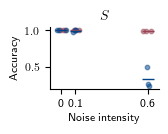

In [ ]:
# Plot for animal identity task
fig_S, ax_S = plt.subplots(figsize=(1.4, 0.8))
# plot mean accuracy for each noise level as a horizontal line and scatter points for each individual value
ax_S.scatter([noise_val + np.random.randn() * 0.02 for noise_val in noise_levels for _ in range(len(noise_df_list))], 
             [noise_df[(noise_df.task == 'sprite_idx') & (noise_df.method == 'pred')]['accuracy'].values for noise_df in noise_df_list],
            color=method_colors['pred'], marker='o', alpha=0.5, s=10)
ax_S.scatter([noise_val + np.random.randn() * 0.02 for noise_val in noise_levels for _ in range(len(noise_df_list))], 
             [noise_df[(noise_df.task == 'sprite_idx') & (noise_df.method == 'pred-mem')]['accuracy'].values for noise_df in noise_df_list],
            color=method_colors['pred-mem'], marker='o', alpha=0.5, s=10)
# plot mean accuracy for each noise level as a horizontal line
for i in range(len(noise_levels)):
    ax_S.hlines(noise_df_list[i][(noise_df_list[i].task == 'sprite_idx') & (noise_df_list[i].method == 'pred')]['accuracy'].mean(), 
                noise_levels[i] - 0.04, noise_levels[i] + 0.04, color=method_colors['pred'], linewidth=1, alpha=1)
    ax_S.hlines(noise_df_list[i][(noise_df_list[i].task == 'sprite_idx') & (noise_df_list[i].method == 'pred-mem')]['accuracy'].mean(), 
                noise_levels[i] - 0.04, noise_levels[i] + 0.04, color=method_colors['pred-mem'], linewidth=1, alpha=1)
ax_S.set_xlabel(r'Noise intensity', fontsize=8)
ax_S.set_ylabel('Accuracy', fontsize=8)
ax_S.set_title(r'$S$', fontsize=10)
ax_S.set_xticks(noise_levels)
ax_S.set_xticklabels(["0", "0.1", "0.6"])
sns.despine(ax=ax_S, offset=0)
# Save the figure
fig_S.savefig(os.path.join(savedir, 'fig_noise_effect_S_scatter.pdf'), bbox_inches='tight', dpi=300, transparent=True)

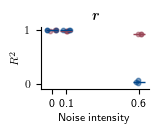

In [ ]:
# Plot for position tasks
fig_r, ax_r = plt.subplots(figsize=(1.4, 0.8))
# plot mean R2 for each noise level as a horizontal line and scatter points for each individual value
position_values = {"pred": [], "pred-mem": []}
for noise_df in noise_df_list:
    position_pred = noise_df[(noise_df.task.isin(['x-position', 'y-position', 'z-position'])) & (noise_df.method == 'pred')]
    position_pred_mem = noise_df[(noise_df.task.isin(['x-position', 'y-position', 'z-position'])) & (noise_df.method == 'pred-mem')]
    if position_pred.empty or position_pred_mem.empty:
        continue
    position_values["pred"].append(position_pred.groupby('seed')['r2'].mean().values)
    position_values["pred-mem"].append(position_pred_mem.groupby('seed')['r2'].mean().values)
ax_r.scatter([noise_val + np.random.randn() * 0.02 for noise_val in noise_levels for _ in range(len(noise_df_list))], 
             position_values["pred"],
            color=method_colors['pred'], marker='o', alpha=0.5, s=10)
ax_r.scatter([noise_val + np.random.randn() * 0.02 for noise_val in noise_levels for _ in range(len(noise_df_list))], 
             position_values["pred-mem"],
            color=method_colors['pred-mem'], marker='o', alpha=0.5, s=10)
# plot mean R2 for each noise level as a horizontal line
for i in range(len(noise_levels)):
    ax_r.hlines(position_values["pred"][i].mean(), 
                noise_levels[i] - 0.04, noise_levels[i] + 0.04, color=method_colors['pred'], linewidth=1, alpha=1)
    ax_r.hlines(position_values["pred-mem"][i].mean(), 
                noise_levels[i] - 0.04, noise_levels[i] + 0.04, color=method_colors['pred-mem'], linewidth=1, alpha=1)
ax_r.set_xlabel(r'Noise intensity', fontsize=8)
ax_r.set_ylabel(r'$R^2$', fontsize=8)
ax_r.set_title(r'$\boldsymbol{r}$', fontsize=10)
ax_r.set_xticks(noise_levels)
ax_r.set_xticklabels(["0", "0.1", "0.6"])
sns.despine(ax=ax_r, offset=0)
ax_r.set_ylim(-0.1, 1.05)
# Save the figure
fig_r.savefig(os.path.join(savedir, 'fig_noise_effect_r_scatter.pdf'), bbox_inches='tight', dpi=300, transparent=True)

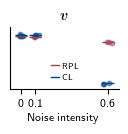

In [ ]:
# Plot for velocity tasks
fig_r, ax_r = plt.subplots(figsize=(1.4, 0.8))
# plot R2 velocity for each noise level as a horizontal line and scatter points for each individual value
velocity_values = {"pred": [], "pred-mem": []}
for noise_df in noise_df_list:
    velocity_pred = noise_df[(noise_df.task.isin(['x-velocity', 'y-velocity', 'z-velocity'])) & (noise_df.method == 'pred')]
    velocity_pred_mem = noise_df[(noise_df.task.isin(['x-velocity', 'y-velocity', 'z-velocity'])) & (noise_df.method == 'pred-mem')]
    if velocity_pred.empty or velocity_pred_mem.empty:
        continue
    velocity_values["pred"].append(velocity_pred.groupby('seed')['r2'].mean().values)
    velocity_values["pred-mem"].append(velocity_pred_mem.groupby('seed')['r2'].mean().values)
ax_r.scatter([noise_val + np.random.randn() * 0.02 for noise_val in noise_levels for _ in range(len(noise_df_list))], 
             velocity_values["pred"],
            color=method_colors['pred'], marker='o', alpha=0.5, s=10)
ax_r.scatter([noise_val + np.random.randn() * 0.02 for noise_val in noise_levels for _ in range(len(noise_df_list))], 
             velocity_values["pred-mem"],
            color=method_colors['pred-mem'], marker='o', alpha=0.5, s=10)
# plot mean R2 for each noise level as a horizontal line
for i in range(len(noise_levels)):
    ax_r.hlines(velocity_values["pred"][i].mean(), 
                noise_levels[i] - 0.04, noise_levels[i] + 0.04, color=method_colors['pred'], linewidth=1, alpha=1)
    ax_r.hlines(velocity_values["pred-mem"][i].mean(), 
                noise_levels[i] - 0.04, noise_levels[i] + 0.04, color=method_colors['pred-mem'], linewidth=1, alpha=1)
ax_r.set_xlabel(r'Noise intensity', fontsize=8)
# ax_r.set_ylabel(r'$R^2$', fontsize=8)
ax_r.set_title(r'$\boldsymbol{v}$', fontsize=10)
# make legend handles
handles = [plt.Line2D([0], [0], color=method_colors['pred'], linestyle='-', linewidth=1, label='RPL'),
           plt.Line2D([0], [0], color=method_colors['pred-mem'], linestyle='-', linewidth=1, label='CL')]
ax_r.legend(handles=handles, fontsize=6, frameon=False, loc="lower center", handletextpad=0.3, handlelength=1)
ax_r.set_xticks(noise_levels)
ax_r.set_xticklabels(["0", "0.1", "0.6"])
ax_r.set_ylim(-0.1, 1.05)
ax_r.set_yticks([])
sns.despine(ax=ax_r, offset=0)
# Save the figure
fig_r.savefig(os.path.join(savedir, 'fig_noise_effect_v_scatter.pdf'), bbox_inches='tight', dpi=300, transparent=True)

# Plot frame dropout effect

In [12]:
occlusion_levels = results_df.n_occluded_frames.unique()
occlusion_levels = np.sort(occlusion_levels[~np.isnan(occlusion_levels)])
occlusion_df_list = []
for occlusion_level in occlusion_levels:
    occlusion_df = results_df[(results_df.n_occluded_frames == occlusion_level) & (results_df.noise_level == 0.1)]
    if occlusion_df.empty:
        continue
    
    # Add a column for the occlusion level
    occlusion_df['n_occluded_frames'] = occlusion_level
    occlusion_df_list.append(occlusion_df)

/tmp/ipykernel_1472657/3182134345.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  occlusion_df['n_occluded_frames'] = occlusion_level


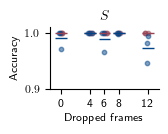

In [ ]:
# Plot for animal identity task
fig_S, ax_S = plt.subplots(figsize=(1.4, 0.8))
# plot mean accuracy for each occlusion level as a horizontal line and scatter points for each individual value
ax_S.scatter([occlusion_val + np.random.randn() * 0.2 for occlusion_val in occlusion_levels for _ in range(3)], 
             [occlusion_df[(occlusion_df.task == 'sprite_idx') & (occlusion_df.method == 'pred')]['accuracy'].values for occlusion_df in occlusion_df_list],
            color=method_colors['pred'], marker='o', alpha=0.5, s=10)
ax_S.scatter([occlusion_val + np.random.randn() * 0.2 for occlusion_val in occlusion_levels for _ in range(3)], 
             [occlusion_df[(occlusion_df.task == 'sprite_idx') & (occlusion_df.method == 'pred-mem')]['accuracy'].values for occlusion_df in occlusion_df_list],
            color=method_colors['pred-mem'], marker='o', alpha=0.5, s=10)
# plot mean accuracy for each occlusion level as a horizontal line
for i in range(len(occlusion_levels)):
    ax_S.hlines(occlusion_df_list[i][(occlusion_df_list[i].task == 'sprite_idx') & (occlusion_df_list[i].method == 'pred')]['accuracy'].mean(), 
                occlusion_levels[i] - 0.8, occlusion_levels[i] + 0.8, color=method_colors['pred'], linewidth=1, alpha=1)
    ax_S.hlines(occlusion_df_list[i][(occlusion_df_list[i].task == 'sprite_idx') & (occlusion_df_list[i].method == 'pred-mem')]['accuracy'].mean(), 
                occlusion_levels[i] - 0.8, occlusion_levels[i] + 0.8, color=method_colors['pred-mem'], linewidth=1, alpha=1)
ax_S.set_xlabel('Dropped frames', fontsize=8)
ax_S.set_ylabel('Accuracy', fontsize=8)
ax_S.set_title(r'$S$', fontsize=10)
ax_S.set_xticks(occlusion_levels)
ax_S.set_xticklabels([f'{ol:.0f}' for ol in occlusion_levels])
ax_S.set_yticks([0.9, 1.0])
ax_S.set_ylim(0.9, 1.01)
sns.despine(ax=ax_S, offset=0)
# Save the figure
fig_S.savefig(os.path.join(savedir, 'fig_occlusion_effect_S_scatter.pdf'), bbox_inches='tight', dpi=300, transparent=True)

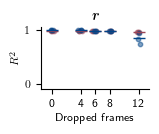

In [ ]:
# Plot for position tasks
fig_r, ax_r = plt.subplots(figsize=(1.4, 0.8))
# plot mean R2 for each occlusion level as a horizontal line and scatter points for each individual value
position_values = {"pred": [], "pred-mem": []}
for occlusion_df in occlusion_df_list:
    position_pred = occlusion_df[(occlusion_df.task.isin(['x-position', 'y-position', 'z-position'])) & (occlusion_df.method == 'pred')]
    position_pred_mem = occlusion_df[(occlusion_df.task.isin(['x-position', 'y-position', 'z-position'])) & (occlusion_df.method == 'pred-mem')]
    if position_pred.empty or position_pred_mem.empty:
        continue
    position_values["pred"].append(position_pred.groupby('seed')['r2'].mean().values)
    position_values["pred-mem"].append(position_pred_mem.groupby('seed')['r2'].mean().values)
ax_r.scatter([occlusion_val + np.random.randn() * 0.2 for occlusion_val in occlusion_levels for _ in range(3)], 
             position_values["pred"],
            color=method_colors['pred'], marker='o', alpha=0.5, s=10)
ax_r.scatter([occlusion_val + np.random.randn() * 0.2 for occlusion_val in occlusion_levels for _ in range(3)], 
             position_values["pred-mem"],
            color=method_colors['pred-mem'], marker='o', alpha=0.5, s=10)
# plot mean R2 for each occlusion level as a horizontal line
for i in range(len(occlusion_levels)):
    ax_r.hlines(position_values["pred"][i].mean(), 
                occlusion_levels[i] - 0.8, occlusion_levels[i] + 0.8, color=method_colors['pred'], linewidth=1, alpha=1)
    ax_r.hlines(position_values["pred-mem"][i].mean(), 
                occlusion_levels[i] - 0.8, occlusion_levels[i] + 0.8, color=method_colors['pred-mem'], linewidth=1, alpha=1)
ax_r.set_xlabel('Dropped frames', fontsize=8)
ax_r.set_ylabel(r'$R^2$', fontsize=8)
ax_r.set_title(r'$\boldsymbol{r}$', fontsize=10)
ax_r.set_xticks(occlusion_levels)
ax_r.set_xticklabels([f'{ol:.0f}' for ol in occlusion_levels])
ax_r.set_ylim(-0.1, 1.05)
sns.despine(ax=ax_r, offset=0)
# Save the figure
fig_r.savefig(os.path.join(savedir, 'fig_occlusion_effect_r_scatter.pdf'), bbox_inches='tight', dpi=300, transparent=True)

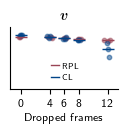

In [ ]:
# Plot for velocity tasks
fig_v, ax_v = plt.subplots(figsize=(1.4, 0.8))
# plot R2 velocity for each occlusion level as a horizontal line and scatter points for each individual value
velocity_values = {"pred": [], "pred-mem": []}
for occlusion_df in occlusion_df_list:
    velocity_pred = occlusion_df[(occlusion_df.task.isin(['x-velocity', 'y-velocity', 'z-velocity'])) & (occlusion_df.method == 'pred')]
    velocity_pred_mem = occlusion_df[(occlusion_df.task.isin(['x-velocity', 'y-velocity', 'z-velocity'])) & (occlusion_df.method == 'pred-mem')]
    if velocity_pred.empty or velocity_pred_mem.empty:
        continue
    velocity_values["pred"].append(velocity_pred.groupby('seed')['r2'].mean().values)
    velocity_values["pred-mem"].append(velocity_pred_mem.groupby('seed')['r2'].mean().values)
ax_v.scatter([occlusion_val + np.random.randn() * 0.2 for occlusion_val in occlusion_levels for _ in range(3)], 
             velocity_values["pred"],
            color=method_colors['pred'], marker='o', alpha=0.5, s=10)
ax_v.scatter([occlusion_val + np.random.randn() * 0.2 for occlusion_val in occlusion_levels for _ in range(3)], 
             velocity_values["pred-mem"],
            color=method_colors['pred-mem'], marker='o', alpha=0.5, s=10)
# plot mean R2 for each occlusion level as a horizontal line
for i in range(len(occlusion_levels)):
    ax_v.hlines(velocity_values["pred"][i].mean(), 
                occlusion_levels[i] - 0.8, occlusion_levels[i] + 0.8, color=method_colors['pred'], linewidth=1, alpha=1)
    ax_v.hlines(velocity_values["pred-mem"][i].mean(), 
                occlusion_levels[i] - 0.8, occlusion_levels[i] + 0.8, color=method_colors['pred-mem'], linewidth=1, alpha=1)
ax_v.set_xlabel('Dropped frames', fontsize=8)
# ax_v.set_ylabel(r'$R^2$', fontsize=8)
ax_v.set_title(r'$\boldsymbol{v}$', fontsize=10)
# make legend handles
handles = [plt.Line2D([0], [0], color=method_colors['pred'], linestyle='-', linewidth=1, label='RPL'),
           plt.Line2D([0], [0], color=method_colors['pred-mem'], linestyle='-', linewidth=1, label='CL')]
ax_v.legend(handles=handles, fontsize=6, frameon=False, loc="lower center", handletextpad=0.3, handlelength=1)
ax_v.set_xticks(occlusion_levels)
ax_v.set_xticklabels([f'{ol:.0f}' for ol in occlusion_levels])
ax_v.set_ylim(-0.1, 1.05)
ax_v.set_yticks([])
sns.despine(ax=ax_v, offset=0)
# Save the figure
fig_v.savefig(os.path.join(savedir, 'fig_occlusion_effect_v_scatter.pdf'), bbox_inches='tight', dpi=300, transparent=True)